Next part , implementing the ViT model and comparing it to what we had in previous step

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

from tqdm import tqdm, trange

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader, TensorDataset

import struct
import kagglehub
from pathlib import Path

np.random.seed(0)
torch.manual_seed(0)

In [2]:
# download mnist dataset from kaggle (same data as part 1)
path = kagglehub.dataset_download("hojjatk/mnist-dataset")
root = Path(path)

def read_images(p):
    with open(p, "rb") as f:
        _, n, r, c = struct.unpack(">IIII", f.read(16))
        return torch.from_numpy(np.frombuffer(f.read(), dtype=np.uint8).copy()).view(n, 1, r, c).float() / 255

def read_labels(p):
    with open(p, "rb") as f:
        f.read(8)
        return torch.from_numpy(np.frombuffer(f.read(), dtype=np.uint8).copy()).long()

def find_file(prefix):
    # match real files only, skip the same-named folders
    return next(p for p in root.rglob(prefix + "*") if p.is_file())

Xtr = read_images(find_file("train-images"))
ytr = read_labels(find_file("train-labels"))
Xte = read_images(find_file("t10k-images"))
yte = read_labels(find_file("t10k-labels"))

print(Xtr.shape, ytr.shape, Xte.shape, yte.shape)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
torch.Size([60000, 1, 28, 28]) torch.Size([60000]) torch.Size([10000, 1, 28, 28]) torch.Size([10000])


In [3]:
def main():
    # Loading data (pixels between 0 and 1, loaded in the cell above)
    train_loader = DataLoader(TensorDataset(Xtr, ytr), shuffle=True, batch_size=128)
    test_loader = DataLoader(TensorDataset(Xte, yte), shuffle=False, batch_size=128)

    # Defining model and training options
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Using device: ", device, f"({torch.cuda.get_device_name(device)})" if torch.cuda.is_available() else "")
    model = MyViT((1, 28, 28), n_patches=7, n_blocks=4, hidden_d=64, n_heads=4, out_d=10).to(device)
    N_EPOCHS = 10
    LR = 0.001

    # Training loop
    optimizer = Adam(model.parameters(), lr=LR)
    criterion = CrossEntropyLoss()
    train_losses = []
    t0 = time.time()
    for epoch in trange(N_EPOCHS, desc="Training"):
        train_loss = 0.0
        for batch in tqdm(train_loader, desc=f"Epoch {epoch + 1} in training", leave=False):
            x, y = batch
            x, y = x.to(device), y.to(device)
            y_hat = model(x)
            loss = criterion(y_hat, y)

            train_loss += loss.detach().cpu().item() / len(train_loader)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_losses.append(train_loss)
        print(f"Epoch {epoch + 1}/{N_EPOCHS} loss: {train_loss:.4f}")
    train_time = time.time() - t0

    # Test loop
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Testing"):
            x, y = batch
            x = x.to(device)
            all_logits.append(model(x).cpu())
            all_labels.append(y)
    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)
    preds = logits.argmax(dim=1)

    # metrics on the full test set and on the first 2000 images (same images as in part 1)
    results = {}
    for name, n in [("full", len(labels)), ("sub", 2000)]:
        results[name] = {
            "accuracy": 100 * accuracy_score(labels[:n], preds[:n]),
            "f1": 100 * f1_score(labels[:n], preds[:n], average="macro"),
            "loss": F.cross_entropy(logits[:n], labels[:n]).item(),
        }
    results["train_time_s"] = train_time
    results["params_M"] = sum(p.numel() for p in model.parameters()) / 1e6

    print(f"Test loss: {results['full']['loss']:.4f}")
    print(f"Test accuracy: {results['full']['accuracy']:.2f}%")
    print(f"Test F1: {results['full']['f1']:.2f}%")
    print(f"Training time: {train_time:.1f} s | Params: {results['params_M']:.3f} M")
    return model, results, train_losses

In [4]:
def patchify(images, n_patches):
    n, c, h, w = images.shape

    assert h == w, "Patchify method is implemented for square images only"

    patches = torch.zeros(n, n_patches ** 2, h * w * c // n_patches ** 2, device=images.device)
    patch_size = h // n_patches

    for i in range(n_patches):
        for j in range(n_patches):
            patch = images[:, :, i * patch_size: (i + 1) * patch_size, j * patch_size: (j + 1) * patch_size]
            patches[:, i * n_patches + j] = patch.flatten(start_dim=1)
    return patches

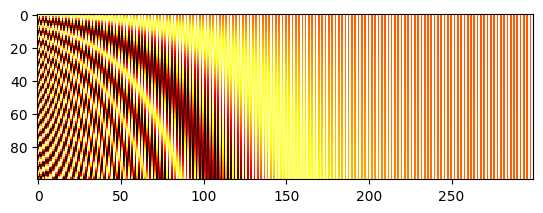

In [5]:
def get_positional_embeddings(sequence_length, d):
    result = torch.ones(sequence_length, d)
    for i in range(sequence_length):
        for j in range(d):
            result[i][j] = np.sin(i / (10000 ** (j / d))) if j % 2 == 0 else np.cos(i / (10000 ** ((j - 1) / d)))
    return result

if __name__ == "__main__":
  import matplotlib.pyplot as plt

  plt.imshow(get_positional_embeddings(100, 300), cmap="hot", interpolation="nearest")
  plt.show()

In [6]:
class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super(MyMSA, self).__init__()
        self.d = d
        self.n_heads = n_heads

        assert d % n_heads == 0, f"Can't divide dimension {d} into {n_heads} heads"

        d_head = int(d / n_heads)
        self.q_mappings = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(self.n_heads)])
        self.k_mappings = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(self.n_heads)])
        self.v_mappings = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(self.n_heads)])
        self.d_head = d_head
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, sequences):
        # Sequences has shape (N, seq_length, token_dim)
        # Each head works on its own part of the token_dim, then we concatenate the heads
        # We come back to    (N, seq_length, item_dim)
        result = []
        for head in range(self.n_heads):
            q_mapping = self.q_mappings[head]
            k_mapping = self.k_mappings[head]
            v_mapping = self.v_mappings[head]

            seq = sequences[:, :, head * self.d_head: (head + 1) * self.d_head]
            q, k, v = q_mapping(seq), k_mapping(seq), v_mapping(seq)

            attention = self.softmax(q @ k.transpose(1, 2) / (self.d_head ** 0.5))
            result.append(attention @ v)
        return torch.cat(result, dim=-1)

In [7]:
class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super(MyViTBlock, self).__init__()
        self.hidden_d = hidden_d
        self.n_heads = n_heads

        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d)
        )

    def forward(self, x):
        # attention with a residual connection, then mlp with a residual connection
        out = x + self.mhsa(self.norm1(x))
        out = out + self.mlp(self.norm2(out))
        return out

In [8]:
class MyViT(nn.Module):
    def __init__(self, chw, n_patches=7, n_blocks=2, hidden_d=8, n_heads=2, out_d=10):
        # Super constructor
        super(MyViT, self).__init__()
        
        # Attributes
        self.chw = chw # ( C , H , W )
        self.n_patches = n_patches
        self.n_blocks = n_blocks
        self.n_heads = n_heads
        self.hidden_d = hidden_d
        
        # Input and patches sizes
        assert chw[1] % n_patches == 0, "Input shape not entirely divisible by number of patches"
        assert chw[2] % n_patches == 0, "Input shape not entirely divisible by number of patches"
        self.patch_size = (chw[1] / n_patches, chw[2] / n_patches)

        # 1) Linear mapper
        self.input_d = int(chw[0] * self.patch_size[0] * self.patch_size[1])
        self.linear_mapper = nn.Linear(self.input_d, self.hidden_d)
        
        # 2) Learnable classification token
        self.class_token = nn.Parameter(torch.rand(1, self.hidden_d))
        
        # 3) Positional embedding
        self.register_buffer('positional_embeddings', get_positional_embeddings(n_patches ** 2 + 1, hidden_d), persistent=False)
        
        # 4) Transformer encoder blocks
        self.blocks = nn.ModuleList([MyViTBlock(hidden_d, n_heads) for _ in range(n_blocks)])

        # 5) Classification MLP (no softmax here, CrossEntropyLoss already does it)
        self.mlp = nn.Linear(self.hidden_d, out_d)

    def forward(self, images):
        # Dividing images into patches
        n, c, h, w = images.shape
        patches = patchify(images, self.n_patches).to(self.positional_embeddings.device)
        
        # Running linear layer tokenization
        # Map the vector corresponding to each patch to the hidden size dimension
        tokens = self.linear_mapper(patches)
        
        # Adding classification token to the tokens
        tokens = torch.cat((self.class_token.expand(n, 1, -1), tokens), dim=1)
        
        # Adding positional embedding
        out = tokens + self.positional_embeddings.repeat(n, 1, 1)
        
        # Transformer Blocks
        for block in self.blocks:
            out = block(out)

        # Getting the classification token only
        out = out[:, 0]

        return self.mlp(out)

In [9]:
if __name__ == '__main__':
  # Current model
  model = MyViT(
    chw=(1, 28, 28),
    n_patches=7
  )

  x = torch.randn(7, 1, 28, 28) # Dummy images
  print(model(x).shape) # torch.Size([7, 10])

torch.Size([7, 10])


In [10]:
vit_model, vit_results, vit_losses = main()

Using device:  cuda (Tesla T4)


Training:  10%|█         | 1/10 [00:12<01:49, 12.19s/it]

Epoch 1/10 loss: 0.8416


Training:  20%|██        | 2/10 [00:24<01:36, 12.03s/it]

Epoch 2/10 loss: 0.1931


...

Epoch 9/10 loss: 0.0507


Training: 100%|██████████| 10/10 [01:59<00:00, 11.91s/it]


Epoch 10/10 loss: 0.0491


Testing: 100%|██████████| 79/79 [00:00<00:00, 117.10it/s]

Test loss: 0.0587
Test accuracy: 98.18%
Test F1: 98.17%
Training time: 119.1 s | Params: 0.148 M


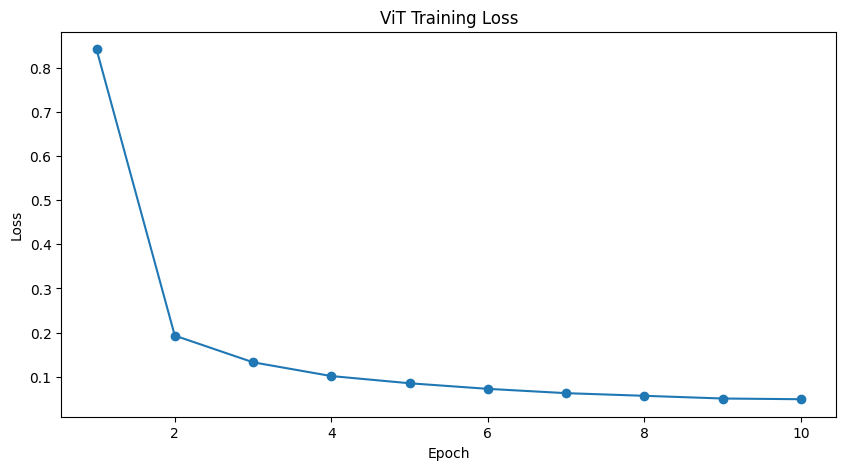

In [11]:
# training loss of the vit
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(vit_losses) + 1), vit_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training Loss")
plt.show()

#### comparison with part 1

the numbers of part 1 are copied from its final table (first 2000 test images). the ViT is trained on all 60k images, like the first CNN

In [12]:
# part 1 results copied from the last table of part1_cnn_rcnn.ipynb
part1 = {
    "CNN":                          ["60k images, 5 epochs",  98.80, 98.787, 0.036, 17.741, 0.099],
    "Faster R-CNN":                 ["10000 images, 2 epochs", 98.50, 98.513, 0.529, 119.109, 18.976],
    "CNN (same data)":              ["10000 images, 2 epochs", 96.80, 96.802, 0.099, 1.161, 0.099],
    "AlexNet (frozen)":             ["10000 images, 2 epochs, features frozen", 97.55, 97.528, 0.082, 12.003, 57.045],
    "VGG16 (frozen)":               ["10000 images, 2 epochs, features frozen", 97.50, 97.504, 0.069, 104.348, 134.302],
    "AlexNet (last block unfrozen)": ["10000 images, 2 epochs, last conv block unfrozen", 97.60, 97.607, 0.077, 13.377, 57.045],
    "VGG16 (last block unfrozen)":  ["10000 images, 2 epochs, last conv block unfrozen", 97.35, 97.369, 0.077, 120.000, 134.302],
}

s = vit_results["sub"]
part1["ViT"] = ["60k images, 10 epochs", s["accuracy"], s["f1"], s["loss"], vit_results["train_time_s"], vit_results["params_M"]]

table = pd.DataFrame(part1, index=["Setup", "Accuracy (%)", "F1 macro (%)", "Loss", "Training time (s)", "Params (M)"]).T
for col in table.columns[1:]:
    table[col] = table[col].astype(float).round(3)
display(table)

print("ViT on the full test set:", vit_results["full"])

,Setup,Accuracy (%),F1 macro (%),Loss,Training time (s),Params (M)
CNN,"60k images, 5 epochs",98.80,98.787,0.036,17.741,0.099
Faster R-CNN,"10000 images, 2 epochs",98.50,98.513,0.529,119.109,18.976
CNN (same data),"10000 images, 2 epochs",96.80,96.802,0.099,1.161,0.099
AlexNet (frozen),"10000 images, 2 epochs, features frozen",97.55,97.528,0.082,12.003,57.045
VGG16 (frozen),"10000 images, 2 epochs, features frozen",97.50,97.504,0.069,104.348,134.302
AlexNet (last block unfrozen),"10000 images, 2 epochs, last conv block unfrozen",97.60,97.607,0.077,13.377,57.045
VGG16 (last block unfrozen),"10000 images, 2 epochs, last conv block unfrozen",97.35,97.369,0.077,120.000,134.302
ViT,"60k images, 10 epochs",97.75,97.732,0.078,119.137,0.148


ViT on the full test set: {'accuracy': 98.18, 'f1': 98.1669962500811, 'loss': 0.058693256229162216}


#### Conclusion:

The ViT reaches 97.75% accuracy on the 2000 test images (98.18% on the full test set), with 0.148M parameters. It is better than the CNN trained on the same small data (96.8%) and about equal to the pretrained AlexNet and VGG16 (about 97.5%), which have 400 to 900 times more parameters. Faster R-CNN (98.5%) is a bit better, but it starts from pretrained weights and is much heavier.

But the CNN trained on all the images stays the best model: 98.80% accuracy and a loss of 0.036, against 97.75% and 0.078 for the ViT. The ViT is also slower: about 12 seconds per epoch against about 3.5 seconds for the CNN, with a similar number of parameters, because the self-attention compares every patch with every other patch.

The reason is that a CNN already knows how images work (local filters, the same filter used everywhere in the image), while the ViT has to learn this from the data. MNIST is small and simple, so the CNN has the advantage. ViTs become better than CNNs when they are trained on very large datasets or pretrained, which was not the case here.

So for MNIST, the small CNN is still the best choice. The ViT is a good alternative that works well even with a very small model, and it could improve with more epochs, data augmentation, or more patches (smaller patch size).

Note: the ViT was trained for 10 epochs and the first CNN for 5 epochs, and the test subset has only 2000 images, so differences smaller than about 0.3% are not significant.